In [81]:
import numpy as np
import matplotlib.pyplot as plt
import pygame

In [82]:
#updates acceleration based on Newton's laws of gravitation
def acceleration(G, m, r):
    a = np.zeros_like(r)
    for i in range(len(m)):
        for j in range(len(m)):
            if(i != j):
                a[i] += -G*m[j]*(r[i]-r[j])/np.linalg.norm(r[i]-r[j])**3
    return a

In [83]:
#calculates the derivative of a "state"
def derivative(G, m, S):
    r = S[0]
    v = S[1]
    a = acceleration(G, m, r)
    return np.array([v, a])

In [84]:
#advances the simulation using the explicit Euler method (not stable)
def update_explicit_euler(G, m, ri, vi, dt):
    a = acceleration(G, m, ri)
    rf = ri + vi * dt
    vf = vi + a * dt
    return rf, vf

In [85]:
#advances the simulation using the implicit Euler method (always stable)
def update_implicit_euler(G, m, ri, vi, dt):
    a = acceleration(G, m, ri)
    vf = vi + a * dt
    rf = ri + vf * dt
    return rf, vf

In [86]:
#advances the simulation using the velocity verlet method (generally best method)
def update_velocity_verlet(G, m, ri, vi, ai, dt):
    v_1 = vi + 1/2 * ai * dt
    rf = ri + v_1 * dt
    af = acceleration(G, m, rf)
    vf = v_1 + 1/2 * af * dt
    return rf, vf, af

In [87]:
#advances the simulation using the fourth-order Runge-Kutta method (RK4)
def update_rk4(G, m, ri, vi, dt):
    Si = np.array([ri, vi])
    k1 = derivative(G, m, Si)
    k2 = derivative(G, m, Si + k1*(dt/2))
    k3 = derivative(G, m, Si + k2*(dt/2))
    k4 = derivative(G, m, Si + k3*dt)
    Sf = Si + (dt/6) * (k1 + 2*k2 + 2*k3 + k4)
    return Sf[0], Sf[1]

In [88]:
#calculates the current kinetic and potential energies
def energy(G, m, r, v):
    U = 0
    E_kin = 0
    for i in range(len(m)):
        E_kin += 1/2 * m[i] * np.linalg.norm(v[i])**2
        for j in range(i+1, len(m), 1):
            U += -G * m[i] * m[j] / np.linalg.norm(r[i]-r[j])
    return U, E_kin

In [89]:
#pygame setup
W, H = 800, 600
pygame.init()
screen = pygame.display.set_mode((W, H))
pygame.display.set_caption("n-body problem simulation")
clock = pygame.time.Clock()
running = True

#general constants and parameters of the simulation
G=10
dt=0.01

R = 3
colors = ["yellow", "blue", "red", "green", "purple", "white", "orange"]
show_path = False

methods = ["explicit_euler", "implicit_euler", "velocity_verlet", "rk4"]
method = methods[2]

#mass, position, velocity and acceleration matrices
m = np.array([1000,1000,10])

r1 = np.array([350.0, 600.0])
r2 = np.array([450.0, 600.0])
r3 = np.array([200.0, 200.0])
r = np.array([r1,r2,r3])

v1 = np.array([1, 0])
v2 = np.array([0, -10])
v3 = np.array([0, 0])
v = np.array([v1,v2,v3])

a = acceleration(G,m,r)

E = []
U = []

while running:
    for event in pygame.event.get():
        if event.type == pygame.QUIT:
            running = False 

    #drawing the bodies
    if(show_path == False):
        screen.fill("black")
    for i in range(len(m)):
        if(m[i] != 0):
            pygame.draw.circle(screen, colors[i%len(colors)], r[i], R)

    #energy calculation and updating position, velocity and acceleration
    U.append(energy(G,m,r,v)[0])
    E.append(energy(G,m,r,v)[1])
    if(method == "explicit_euler"):
        r,v = update_explicit_euler(G, m, r, v, dt)
    elif(method == "implicit_euler"):
        r,v = update_implicit_euler(G, m, r, v, dt)
    elif(method == "velocity_verlet"):
        r,v,a = update_velocity_verlet(G, m, r, v, a, dt)
    elif(method == "rk4"):
        r,v = update_rk4(G, m, r, v, dt)

    pygame.display.flip()
    clock.tick(0)

pygame.quit()

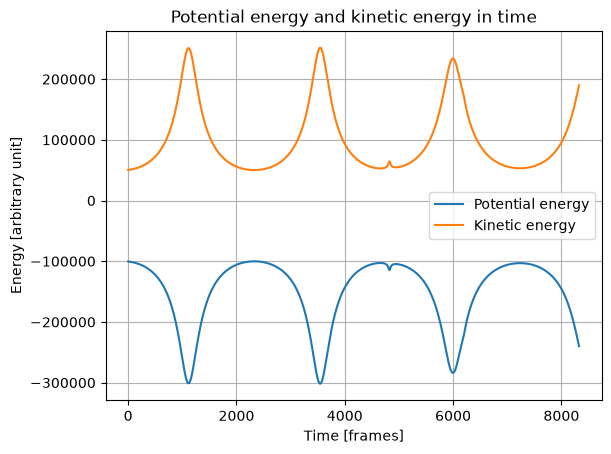

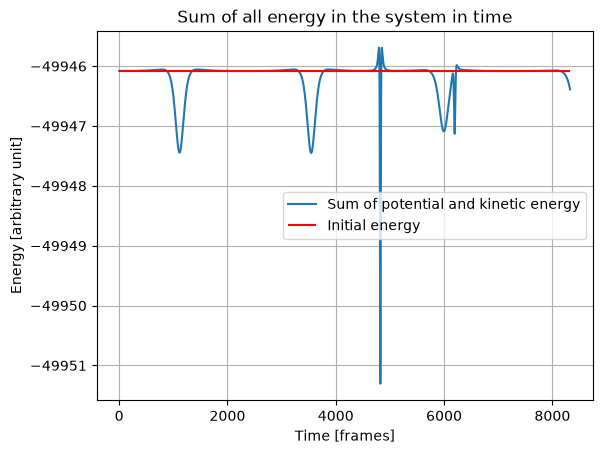

In [ ]:
#plots of energies
plt.figure()
t = range(0,len(E))

plt.plot(t,U, label="Potential energy")
plt.plot(t,E, label="Kinetic energy")
plt.grid()
plt.xlabel("Time [frames]")
plt.ylabel("Energy [arbitrary unit]")
plt.title("Potential energy and kinetic energy in time")
plt.legend()
plt.show()

plt.plot(t,np.add(E,U), label="Sum of potential and kinetic energy")
plt.hlines(E[0]+U[0],t[0],t[-1],"red", label="Initial energy")
plt.grid()
plt.xlabel("Time [frames]")
plt.ylabel("Energy [arbitrary unit]")
plt.title("Sum of all energy in the system in time")
plt.legend()